# Aircraft System Model

### Requirements

* Python3.12 installed
* Pip installed
* Jupyter notebook installed via (VSCode, Jupyter notebook or other)
* xFoil installed with `pathManager.xFoil` pointing to the executable

### Reference Frame and Angle

Using the body reference frame in the image below with the datum at the main wing leading edge along the longitudinal plane


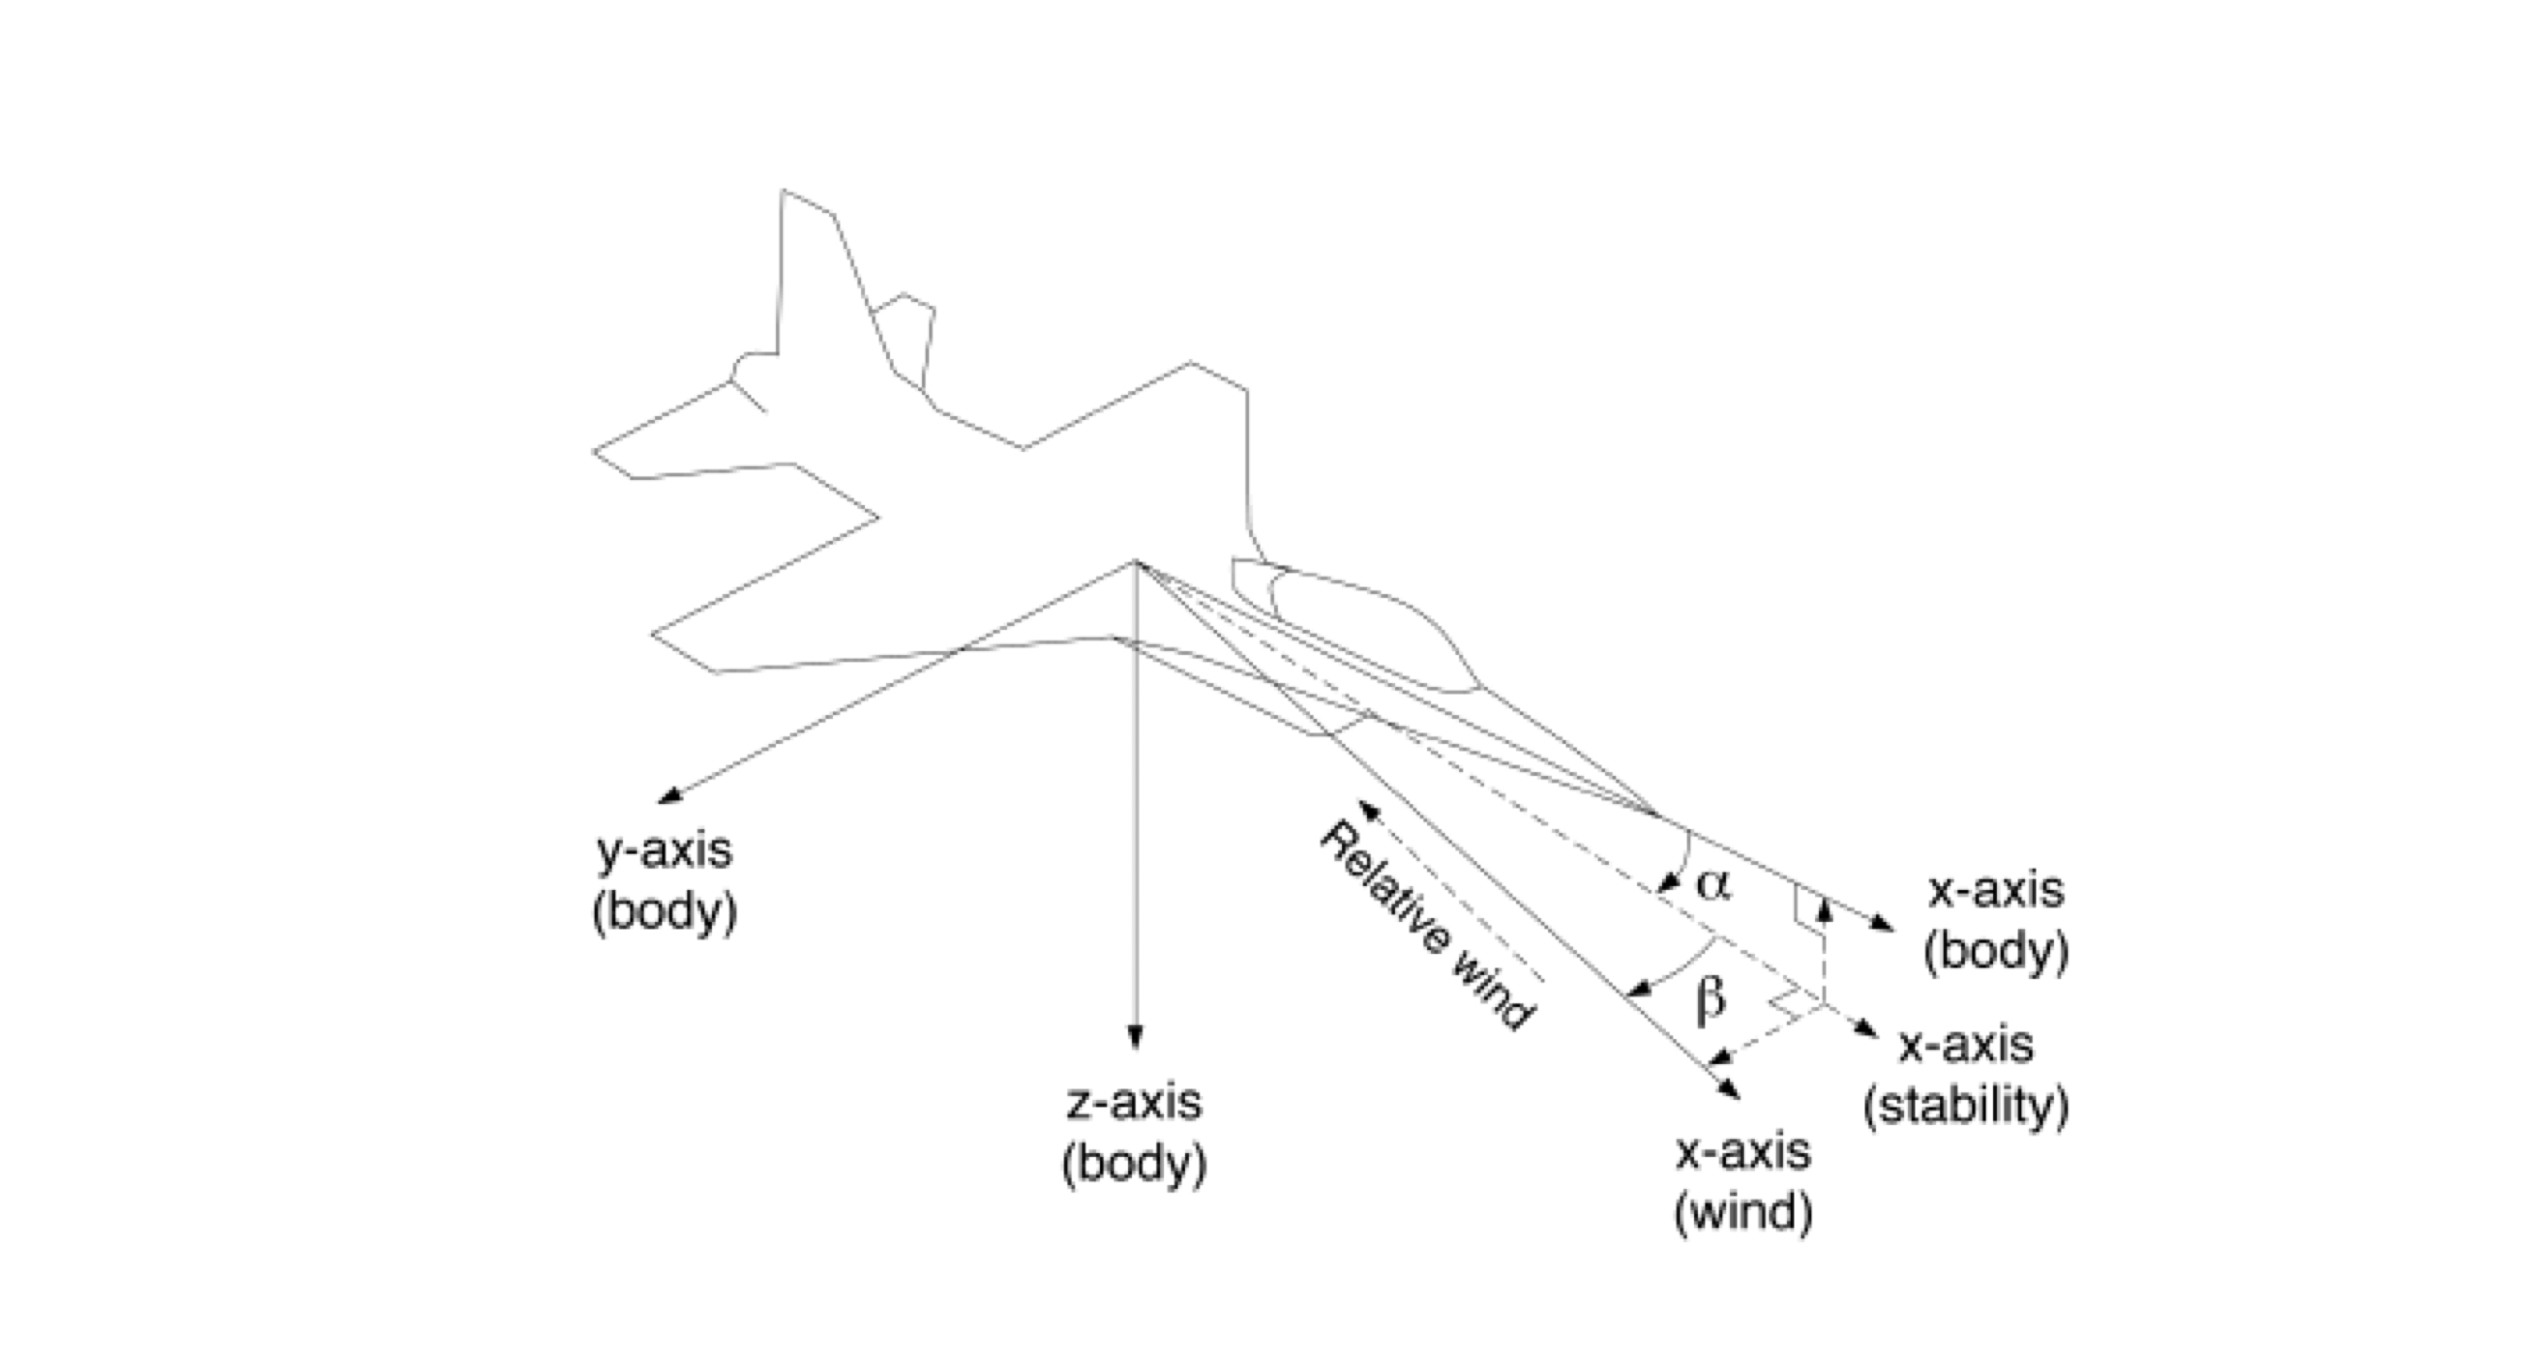


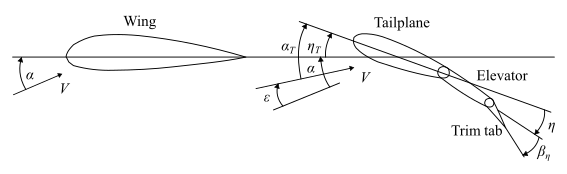

In [1]:
from model.util.jupyter import embed_img
embed_img("docs/images/aircraft-body-reference-frame.jpg")
embed_img("docs/images/aircraft-reference-angle.png")

### Units

All units are SI base units unless otherwise stated.
* length in m
* mass in kg
* angles in degree
* pressure in Pa

### Aerodynamics

Aerodynamic are estimated using a combination of xFoil 2D airfoils and lifting line theory to generate realistic 3d airfoil performance. Aircraft lift coefficients contributions are considered from only the main wing and drag coefficient is considered from all wing surfaces, fuselage and landing gear.

### Structure

All structural loads are considered to be carried by spars. Structural considerations of all others components are ignored. Airfoils are fitted over spars to model wings with the only consideration being geometric compatibility. The mass of both spars and airfoils is estiamted based on gemoetry assuming no material removed as part of weight reductions.

In [2]:
from model.util.jupyter import *

# Install requirements (python modules) and import
try:
    from model.aircraft import *
except ImportError:
    install_requirements()
    from model.aircraft import *

hide_warnings()
enable_crash_logging()

Warnings hidden
Crash logging enabled


### Define assumptions used throughout the model

Define global mass factor applied to all overridden masses and masses estimated from geometry

In [3]:
assumptions.mass_factor = 1.2
assumptions.set_reynolds_number(airspeed=20, wing_chord=300 / 1000)
assumptions.set_mach_number(airspeed=12)

### Define Material

In [4]:
cardboard6mm = Material(
    name="6mm corrugated cardboard",
    ultimate_tensile_strength=1.3e6,
    ultimate_compressive_strength=1e6,
    youngs_modulus=1.8e8,
    shear_modulus=2.1e7,
    density=79,
    nominal_thickness=6 / 1000,
)
print(f"{cardboard6mm.name} area density: {cardboard6mm.area_density:.2f} kg/m^2")

cardboard3mm = Material(
    name="3mm corrugated cardboard",
    ultimate_tensile_strength=1.3e6,
    ultimate_compressive_strength=1e6,
    youngs_modulus=1.8e8,
    shear_modulus=2.1e7,
    density=100,
    nominal_thickness=3 / 1000,
)
print(f"{cardboard3mm.name} area density: {cardboard3mm.area_density:.2f} kg/m^2")

kraft_paper = Material(
    name="kraft paper",
    ultimate_tensile_strength=0,
    ultimate_compressive_strength=0,
    youngs_modulus=0,
    shear_modulus=0,
    density=900,
    nominal_thickness=0.1 / 1000
)
print(f"{kraft_paper.name} area density: {kraft_paper.area_density:.2f} kg/m^2")

6mm corrugated cardboard area density: 0.47 kg/m^2
3mm corrugated cardboard area density: 0.30 kg/m^2
kraft paper area density: 0.09 kg/m^2


### Initial Mass, Assumptions and Requirements

In [5]:
# whole aircraft
total_mass = 5.5

# main wing
main_wing_aspect_ratio = 8
main_wing_oswald_efficiency_factor = 0.8

# requirements
landing_distance = 10
takeoff_distance = 10
climb_angle = 15

### Initial Sizing

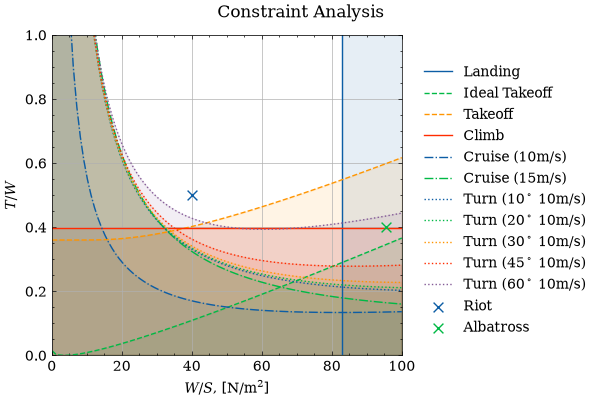

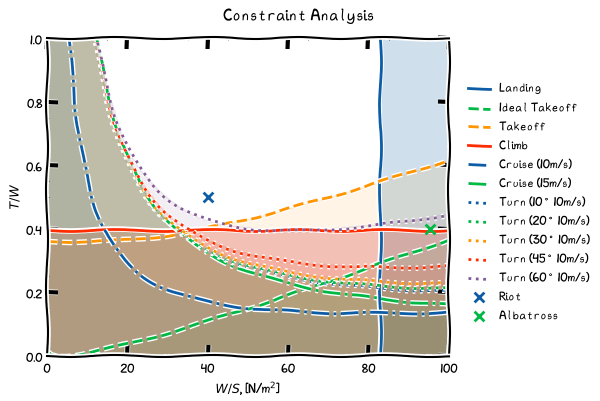

In [6]:
# ? If aircraft mass is known its possible to determine turn constraints for steady level turns. Probably better than airspeed and bank angle

initial_ca = ConstraintAnalysis(
    name="Initial Constraints Analysis",
    aspect_ratio=main_wing_aspect_ratio,
    oswald_efficiency_factor=main_wing_oswald_efficiency_factor,
    zero_lift_drag_coefficient=0.09,
    landing_distance=landing_distance,
    landing_friction_coefficient=0.36, # grass quite coarse long and had lots of dry grass clippings
    landing_lift_coefficient=1.8,
    landing_headwind_speed=2, # [m/s]
    takeoff_distance=takeoff_distance,
    takeoff_lift_coefficient=1.8,
    takeoff_ground_friction_coefficient=0.36, # grass quite coarse long and had lots of dry grass clippings
    takeoff_rolling_drag_coefficient=0,
    takeoff_headwind_speed=2, # [m/s]
    climb_angle_deg=climb_angle,
    climb_lift_coefficient=1.45,
    turn_bank_angle_deg=[10, 20, 30, 45, 60],
    turn_speed=[10, 10, 10, 10, 10],
    cruise_lift_coefficient=1.45,
    cruise_speed=[10, 15],
)

fig = initial_ca.plots.constraint_analysis(
    show=True, save=False,
    design_points=[
        (40, 0.5, "Riot"),
        (95.4, 0.4, "Albatross")
    ])

fig.show(xkcd=True)

### Choose a design point

Initial-Constraints-Analysis.design-point
      Thrust to Weight Ratio  0.547913
        Wing Loading [N/m^2]    82.845
   Takeoff Stall Speed [m/s]     8.669
         Takeoff Speed [m/s]     9.535
   Landing Stall Speed [m/s]     8.669
         Landing Speed [m/s]     8.402
Landing Deceleration [m/s^2]     3.532
        Landing Distance [m]     9.995
     Climb Stall Speed [m/s]     9.658
    Cruise Stall Speed [m/s]     9.658


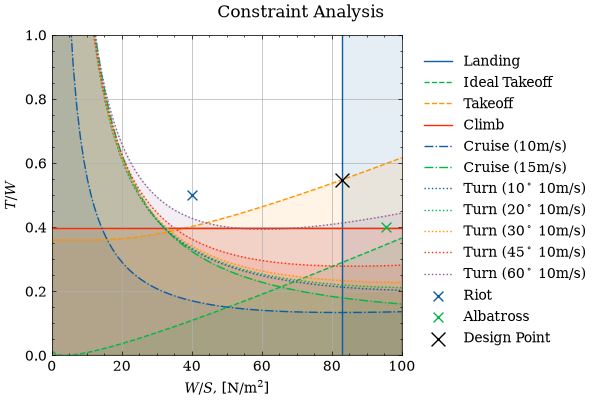

Thrust: 29.563N
Wing Area: 0.651m^2
Wing Span: 1.760m
Wing Chord: 0.370m


In [7]:
# manually choose design point
# ca.set_design_point(53, 0.7)

# automatically set design point
initial_ca.set_optimal_design_point("Min T/W @ Max W/S")

initial_ca.info.design_point(show=True, save=False, transpose=True)
initial_ca.plots.constraint_analysis(
    show=True, save=False,
    design_points=[
        (40, 0.5, "Riot"),
        (95.4, 0.4, "Albatross")
    ])

total_weight = total_mass * 9.81

thrust = initial_ca.design_TW * total_weight
wing_area = total_weight / initial_ca.design_WS

# wing_span = math.sqrt(main_wing_aspect_ratio * wing_area)
# wing_chord = wing_span / main_wing_aspect_ratio

wing_chord = 0.37 # [m] - maximum to fit within the box
wing_span = wing_area / wing_chord
main_wing_aspect_ratio = wing_span / wing_chord

print(f"Thrust: {thrust:.3f}N")
print(f"Wing Area: {wing_area:.3f}m^2")
print(f"Wing Span: {wing_span:.3f}m")
print(f"Wing Chord: {wing_chord:.3f}m")

### Define Load Factor

In [8]:
load_factor = LoadFactors(
    m = total_mass,
    CL = 1.45,
    S_ref=wing_area,
    V_cruise=10,
    bank_angle_deg=30,
    r_turn=50,
    V_turn=10,
    climb_flight_path_angle_deg=15,
)

load_factor.info.overview(show=True, save=False, transpose=True)

load-factor.overview
                    cruise (airspeed: 10.0 m/s)  1.072026
                    level turn (bank: 30.0 deg)     1.155
level turn (radius: 50.0 m, airspeed: 10.0 m/s)     1.021
                                   steady climb     0.966
                   CL required for level cruise     1.353


<Table load-factor.overview>

### Define Aircraft and Fuselage

Please note the fuselage will not be added until either the tail or fin are added

In [9]:
aircraft = Aircraft(
    "Aircraft",
    verbose=True
)

fuselage_material = cardboard6mm

fuselage = FuselageSizing(
    aircraft=aircraft,
    material=fuselage_material,
    width=112 / 1000,
    height=140 / 1000,
    top_thickness=fuselage_material.nominal_thickness * 2,
    bottom_thickness=fuselage_material.nominal_thickness,
    left_thickness=fuselage_material.nominal_thickness,
    right_thickness=fuselage_material.nominal_thickness,
    aft_length=10 / 1000,
    fwd_length=100 / 1000,
    offset=Position(z=150 / 2000)
)

aircraft.add_fuselage(fuselage)

### Main Wing Sizing

Load (per semi-wing) 53.96N
Optimal Height: 42.0mm
Optimal Width: 68.5mm
Optimal Objective Value: 0.05
Airfoil: NACA 4412


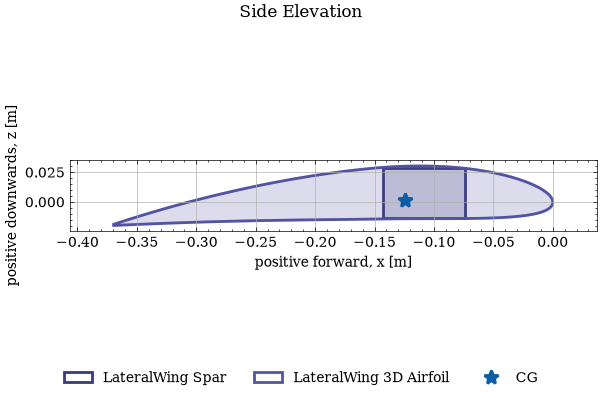

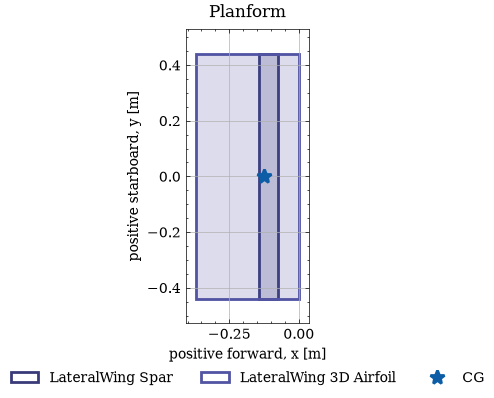

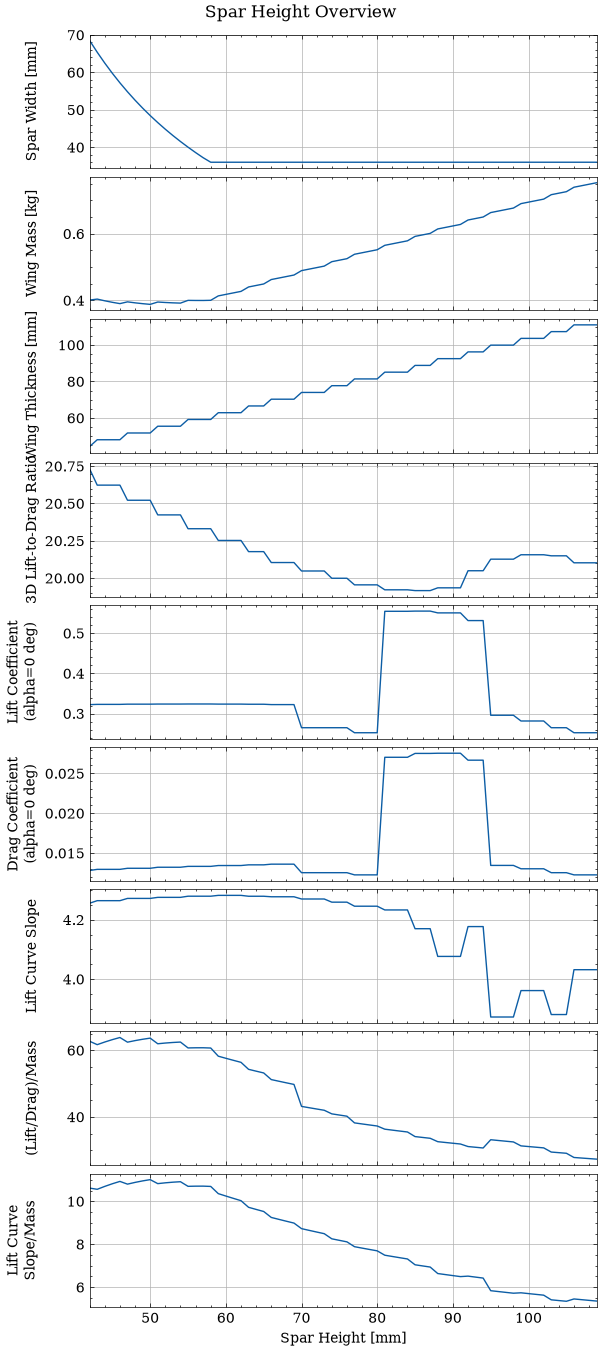

LateralWing.mass-breakdown
                       Name  Mass [kg] Mass Factor  X Position [m]  Y Position [m]  Z Position [m]
                LateralWing      0.401         N/A          -0.124           0.000           0.001
           LateralWing.Spar      0.240       1.200          -0.108           0.000           0.007
     LateralWing.3D Airfoil      0.161       1.200          -0.148           0.000          -0.008
LateralWing.3D Airfoil.Spar      0.240       1.200          -0.108           0.000           0.007


<Table LateralWing.mass-breakdown>

In [10]:
main_wing_load_factor = 2
main_wing_spar_length = wing_span / 2
main_wing_load = (total_weight * main_wing_load_factor)

main_wing_camber = 0.04
main_wing_camber_location = 0.35

main_spar_material = cardboard6mm
main_airfoil_skin_material = kraft_paper
main_airfoil_rib_material = cardboard6mm

main_wing_sizing = MainWingSizing(
    aircraft=aircraft,
    load=main_wing_load,
    S_main=wing_area,
    spar_material=main_spar_material,
    spar_padding=0 / 1000,
    spar_top_thickness=main_spar_material.nominal_thickness * 4,
    spar_bottom_thickness=main_spar_material.nominal_thickness * 3,
    spar_left_thickness=main_spar_material.nominal_thickness * 3,
    spar_right_thickness=main_spar_material.nominal_thickness * 3,
    airfoil_skin_material=main_airfoil_skin_material,
    airfoil_skin_thickness=main_airfoil_skin_material.nominal_thickness,
    airfoil_rib_material=main_airfoil_rib_material,
    airfoil_rib_thickness=main_airfoil_rib_material.nominal_thickness,
    airfoil_rib_spacing=150 / 1000,
    spar_load_distribution=EllipticalWingLoading(),
    spar_min_factor_of_safety=1.0,
    spar_max_deflection=200 / 1000,
    spar_max_deflection_angle=30,
    airfoil_setting_angle=3,
    airfoil_camber=main_wing_camber,
    airfoil_camber_location=main_wing_camber_location,
    airfoil_aspect_ratio=main_wing_aspect_ratio,
    airfoil_spanwise_efficiency_factor=main_wing_oswald_efficiency_factor,
    obj_type="minimise",
    # obj_func=lambda wing: wing.mass.mass,
    # obj_func=lambda wing: wing.airfoil3D.airfoil2d.thickness 
    obj_func=lambda wing: wing.mass.mass * wing.airfoil3D.airfoil2d.thickness,
)

main_wing = main_wing_sizing.optimise_wing(show=True)

main_wing.info.mass_breakdown(show=True, save=False)

### Main Wing Spar Analysis

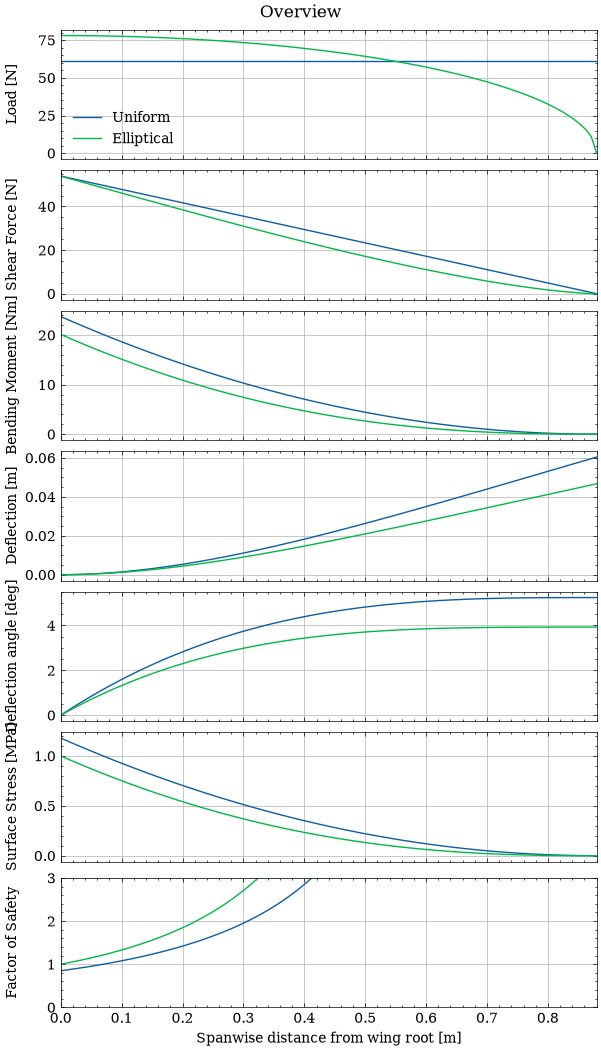

In [11]:
main_wing_spar = main_wing.spar

uniform = main_wing_spar.run_load_model(
    distribution=UniformWingLoading(),
    load=main_wing_load / 2
)
elliptical = main_wing_spar.run_load_model(
    distribution=EllipticalWingLoading(),
    load=main_wing_load / 2
)

combined_plots = (
    uniform.plots.overview(show=False, save=False) +
    elliptical.plots.overview(show=False, save=False)
)
combined_plots.show()

### Main Wing Airfoil Analysis

NACA-4412-3D-Airfoil.overview
                         Name NACA 4412-3D Airfoil
                 Airfoil Name            NACA 4412
                Thickness [m]                0.044
       Semi-Span (Length) [m]                0.880
                    Chord [m]                0.370
                 Aspect Ratio                4.757
          Setting Angle [deg]                    3
          Estimated Mass [kg]                   NA
            Working mass [kg]                0.161
spanwise efficiency factor, e                0.967


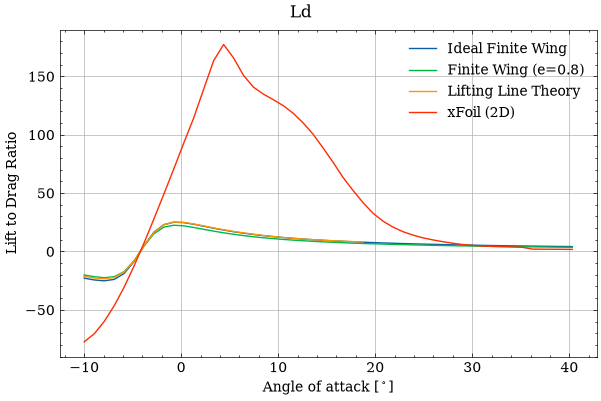

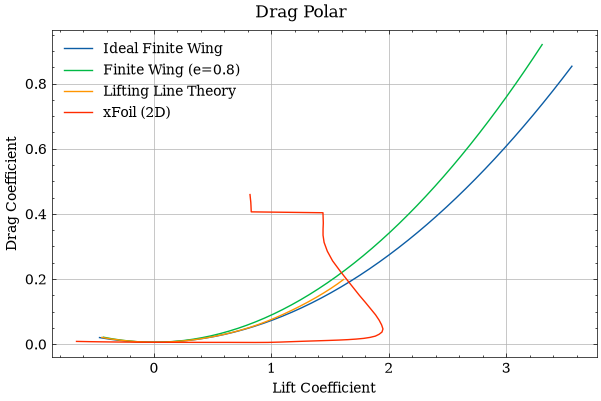

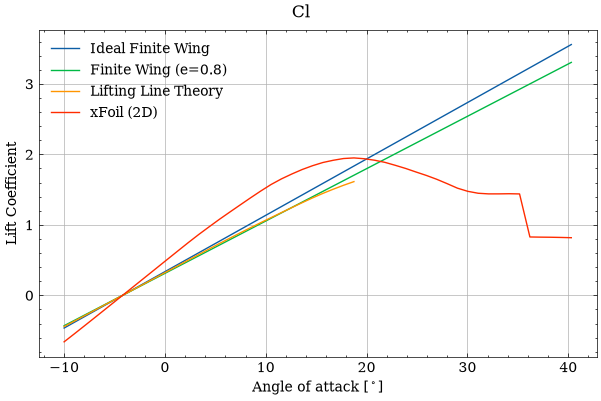

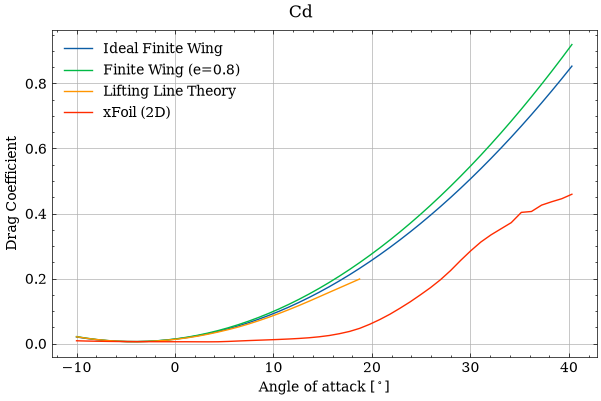

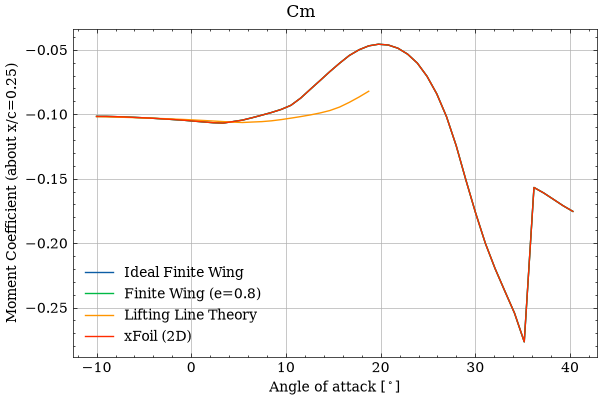

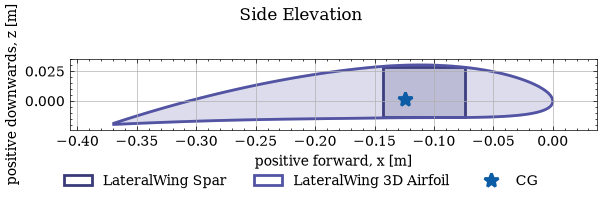

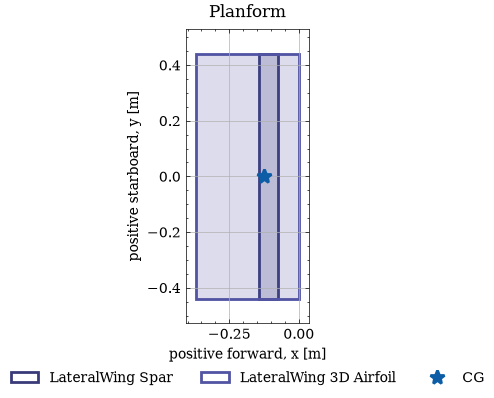

<Plots LateralWing.planform>

In [12]:
airfoil3d = main_wing.airfoil3D

airfoil3d.info.overview(show=True, save=False, transpose=True)
airfoil3d.plots.LD(show=True, save=False)
airfoil3d.plots.drag_polar(show=True, save=False)
airfoil3d.plots.CL(show=True, save=False)
airfoil3d.plots.CD(show=True, save=False)
airfoil3d.plots.CM(show=True, save=False)

main_wing.plots.side_elevation(show=True, save=False, figsize=(6, 2))
main_wing.plots.planform(show=True, save=False)

### Add main wing to aircraft

In [13]:
main_wing.info.geometry(show=True, save=False, transpose=True)

aircraft.add_main_wing(main_wing)

LateralWing.geometry
                   airfoil                NACA 4412
               camber [/c]                    0.040
      camber location [/c]                    0.400
            thickness [/c]                    0.120
                 chord [m]                    0.370
       setting angle [deg]                        3
      length/semi-span [m]                    0.880
     airfoil skin material              kraft paper
airfoil skin thickness [m]                    0.000
      airfoil rib material 6mm corrugated cardboard
 airfoil rib thickness [m]                    0.006
   airfoil rib spacing [m]                    0.150
             spar material 6mm corrugated cardboard
           spar height [m]                    0.042
            spar width [m]                    0.068
    spar top thickness [m]                    0.024
 spar bottom thickness [m]                    0.018
   spar left thickness [m]                    0.018
  spar right thickness [m]                 

### Define Tail

Load (per semi-wing) 2.43N
Optimal Height: 13.0mm
Optimal Width: 18.0mm
Optimal Objective Value: 0.00
Airfoil: NACA 0007


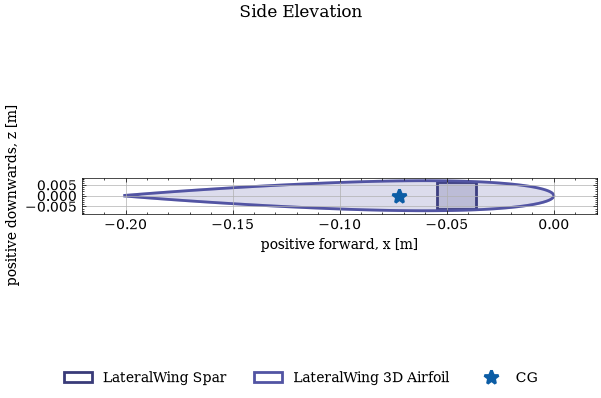

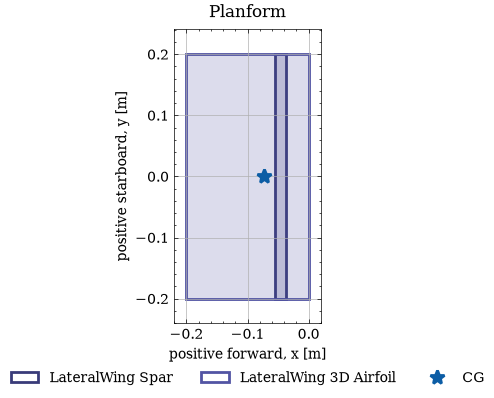

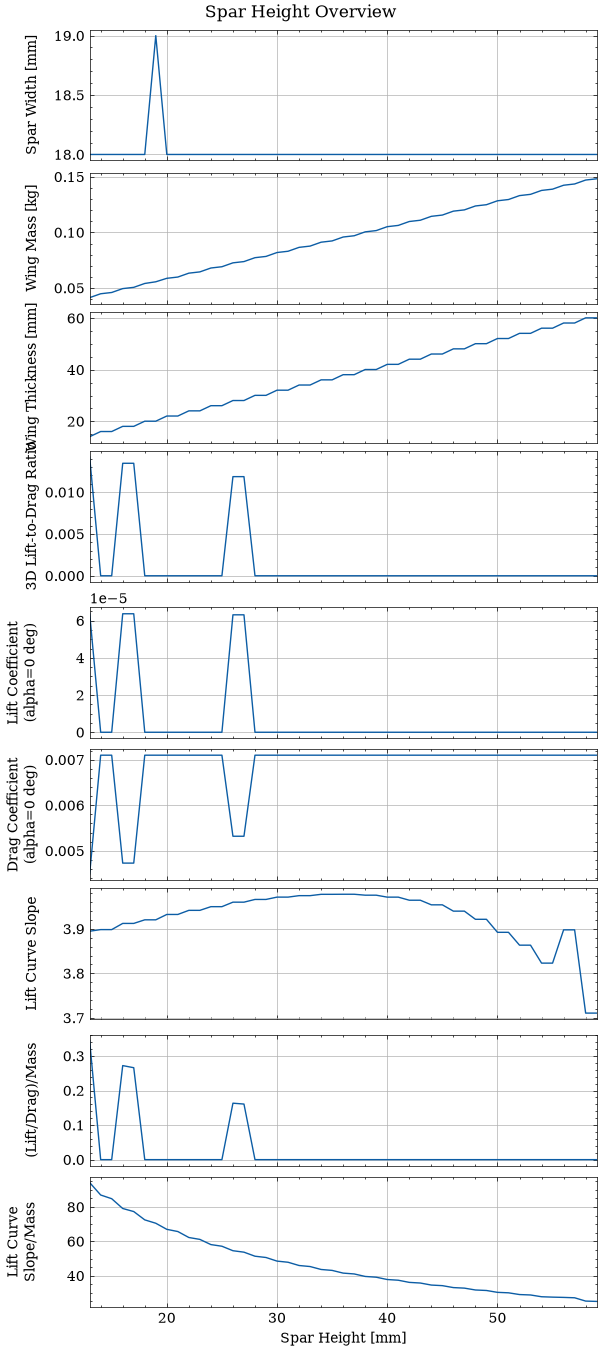

[tail] iter: 0, tail arm error: 163.92mm
[tail] iter: 1, tail arm error: 48.31mm
[tail] iter: 2, tail arm error: 14.83mm
[tail] iter: 3, tail arm error: 4.60mm
[tail] iter: 4, tail arm error: 1.43mm
[tail] iter: 5, tail arm error: 0.45mm
Port-Tail.geometry
                   airfoil                NACA 0007
               camber [/c]                    0.000
      camber location [/c]                    0.000
            thickness [/c]                    0.070
                 chord [m]                    0.200
       setting angle [deg]                        0
      length/semi-span [m]                    0.401
     airfoil skin material              kraft paper
airfoil skin thickness [m]                    0.000
      airfoil rib material 6mm corrugated cardboard
 airfoil rib thickness [m]                    0.006
   airfoil rib spacing [m]                    0.150
             spar material 6mm corrugated cardboard
           spar height [m]                    0.013
            spa

<Table Port-Tail.geometry>

In [14]:
tail_spar_material = cardboard6mm
tail_airfoil_skin_material = kraft_paper
tail_airfoil_rib_material = cardboard6mm
tail_arm = 750 / 1000

tail = TailSizing(
    aircraft=aircraft,
    arm=tail_arm,
    volume_coefficient=0.5,
    downwash_angle=3,
    critical_load_airspeed=15,
    critical_load_angle=5,
    spar_material=tail_spar_material,
    spar_padding=0,
    spar_top_thickness=tail_spar_material.nominal_thickness,
    spar_bottom_thickness=tail_spar_material.nominal_thickness,
    spar_left_thickness=tail_spar_material.nominal_thickness * 2,
    spar_right_thickness=tail_spar_material.nominal_thickness,
    spar_load_distribution=EllipticalWingLoading(),
    spar_min_factor_of_safety=1,
    spar_max_deflection=50 / 1000,
    spar_max_deflection_angle=5,
    airfoil_skin_material=tail_airfoil_skin_material,
    airfoil_skin_thickness=tail_airfoil_skin_material.nominal_thickness,
    airfoil_rib_material=tail_airfoil_rib_material,
    airfoil_rib_thickness=tail_airfoil_rib_material.nominal_thickness,
    airfoil_rib_spacing=150 / 1000,
    airfoil_setting_angle=0,
    airfoil_camber=0,
    airfoil_camber_location=0,
    airfoil_aspect_ratio=4,
    airfoil_spanwise_efficiency_factor=0.8,
    obj_type="minimise",
    # obj_func=lambda wing: wing.airfoil3D.airfoil2d.thickness,
    obj_func=lambda wing: wing.mass.mass * wing.airfoil3D.airfoil2d.thickness,
)

# test
tail.optimise_wing(show=True)

aircraft.add_tail(tail)

aircraft.port_tail_wing.info.geometry(show=True, save=False, transpose=True)

### Define Fin

Load (per semi-wing) 1.21N
Optimal Height: 12.0mm
Optimal Width: 18.0mm
Optimal Objective Value: 0.00
Airfoil: NACA 0010


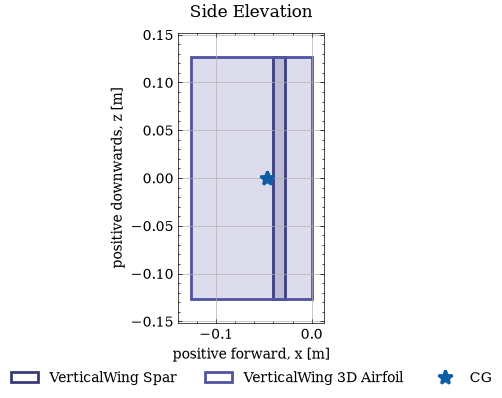

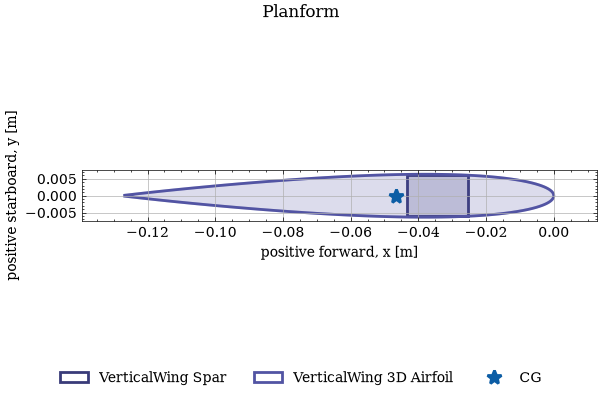

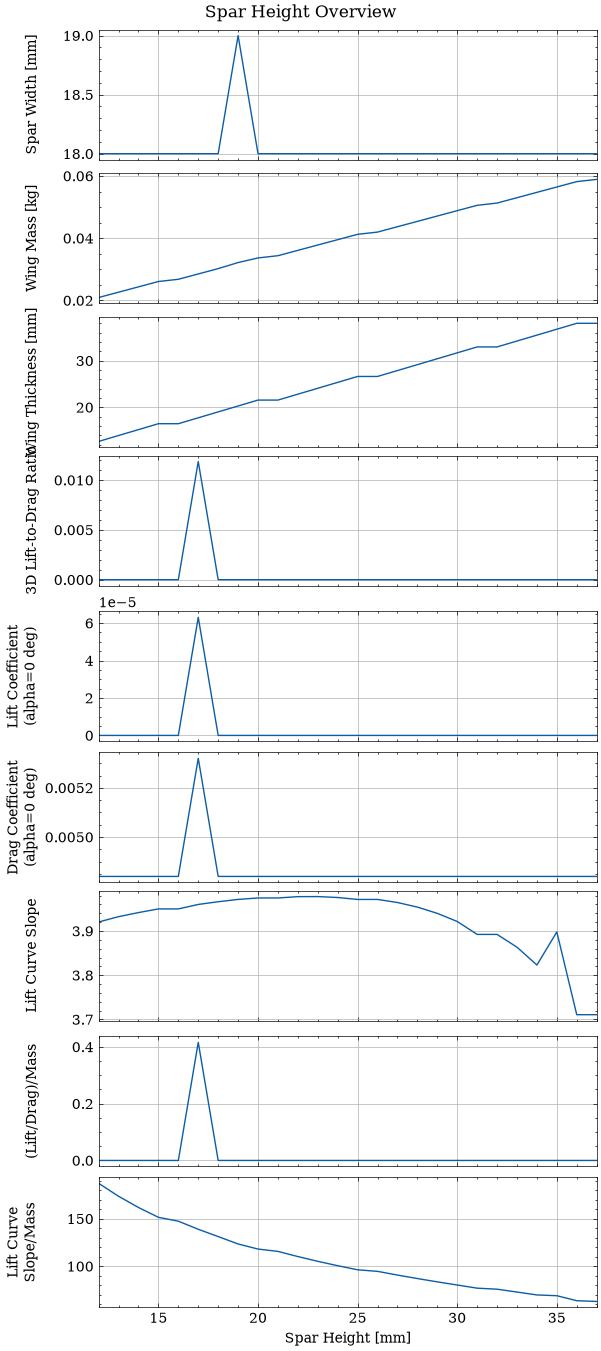

[fin] iter: 0, fin arm error: 11.04mm
[fin] iter: 1, fin arm error: 0.16mm
Fin.geometry
                   airfoil                NACA 0010
               camber [/c]                    0.000
      camber location [/c]                    0.000
            thickness [/c]                    0.100
                 chord [m]                    0.127
       setting angle [deg]                        0
      length/semi-span [m]                    0.253
     airfoil skin material              kraft paper
airfoil skin thickness [m]                    0.000
      airfoil rib material 6mm corrugated cardboard
 airfoil rib thickness [m]                    0.006
   airfoil rib spacing [m]                    0.150
             spar material 6mm corrugated cardboard
           spar height [m]                    0.012
            spar width [m]                    0.018
    spar top thickness [m]                    0.006
 spar bottom thickness [m]                    0.006
   spar left thickness [m]  

<Table Fin.geometry>

In [15]:
fin_spar_material = cardboard6mm
fin_airfoil_skin_material = kraft_paper
fin_airfoil_rib_material = cardboard6mm
fin_arm = tail_arm

fin = FinSizing(
    aircraft=aircraft,
    arm=fin_arm,
    volume_coefficient=0.1,
    critical_load_airspeed=15,
    critical_load_angle=5,
    spar_material=fin_spar_material,
    spar_padding=0,
    spar_top_thickness=fin_spar_material.nominal_thickness,
    spar_bottom_thickness=fin_spar_material.nominal_thickness,
    spar_left_thickness=fin_spar_material.nominal_thickness * 2,
    spar_right_thickness=fin_spar_material.nominal_thickness,
    spar_load_distribution=EllipticalWingLoading(),
    spar_min_factor_of_safety=1,
    spar_max_deflection=50 / 1000,
    spar_max_deflection_angle=5,
    airfoil_skin_material=fin_airfoil_skin_material,
    airfoil_skin_thickness=fin_airfoil_skin_material.nominal_thickness,
    airfoil_rib_material=fin_airfoil_rib_material,
    airfoil_rib_thickness=fin_airfoil_rib_material.nominal_thickness,
    airfoil_rib_spacing=150 / 1000,
    airfoil_setting_angle=0,
    airfoil_camber=0,
    airfoil_camber_location=0,
    airfoil_aspect_ratio=2,
    airfoil_spanwise_efficiency_factor=0.8,
    obj_type="minimise",
    # obj_func=lambda wing: wing.airfoil3D.airfoil2d.thickness,
    obj_func=lambda wing: wing.mass.mass * wing.airfoil3D.airfoil2d.thickness,
)

# test
fin.optimise_wing(show=True)

aircraft.add_fin(fin)

aircraft.fin_wing.info.geometry(show=True, save=False, transpose=True)

### Define Mass Components

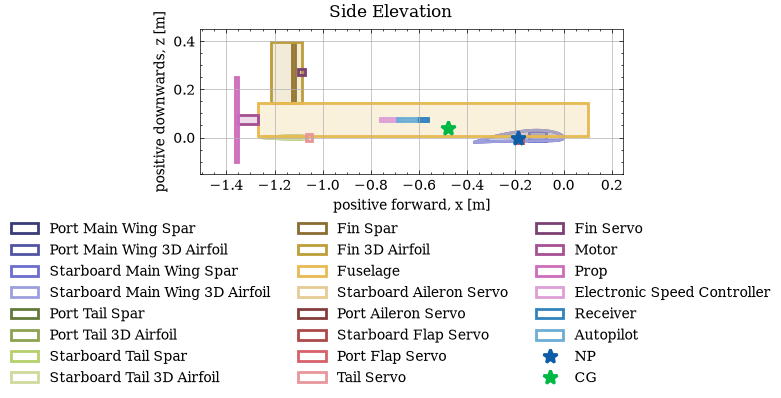

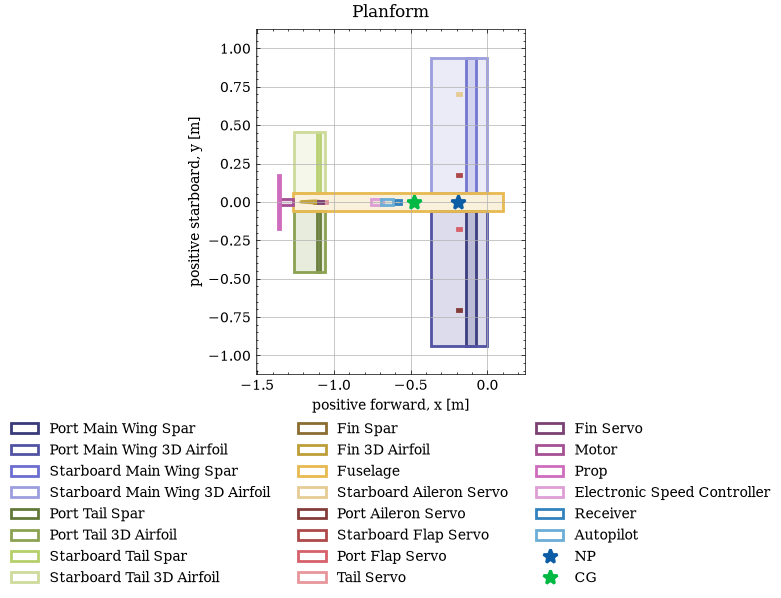

Aircraft.mass-breakdown
                                        Name  Mass [kg] Mass Factor  X Position [m]  Y Position [m]  Z Position [m]
                                    Aircraft      1.853         N/A          -0.482           0.000           0.040
                     Aircraft.Port Main Wing      0.401         N/A          -0.124          -0.496           0.001
                Aircraft.Port Main Wing.Spar      0.240       1.200          -0.108          -0.496           0.007
          Aircraft.Port Main Wing.3D Airfoil      0.161       1.200          -0.148          -0.496          -0.008
     Aircraft.Port Main Wing.3D Airfoil.Spar      0.240       1.200          -0.108          -0.496           0.007
                Aircraft.Starboard Main Wing      0.401         N/A          -0.124           0.496           0.001
           Aircraft.Starboard Main Wing.Spar      0.240       1.200          -0.108           0.496           0.007
     Aircraft.Starboard Main Wing.3D Airfoil    

<Table Aircraft.mass-breakdown>

In [16]:
# quantities quoted from packaging
servo = MassComponent(
    component_name="Servo (ES 3053)",
    mass=Mass(override_mass=17.5 / 1000, override_mass_factor=1),
    dx=28.5 / 1000,
    dy=13.0 / 1000,
    dz=27.0 / 1000
)

aileron_servo = servo.copy("Aileron Servo", offset=lambda: Position(
    x=main_wing.airfoil3D.chordwise_position(0.5).x,
    y=main_wing.spar.length * 0.8,
    z=main_wing.airfoil3D.chordwise_position(0.5).z
))
aircraft.add_mass_component(aileron_servo, mirror_laterally=True)

flap_servo = servo.copy("Flap Servo", offset=lambda: Position(
    x=main_wing.airfoil3D.chordwise_position(0.5).x,
    y=main_wing.spar.length * 0.2,
    z=main_wing.airfoil3D.chordwise_position(0.5).z
))
aircraft.add_mass_component(flap_servo, mirror_laterally=True)

# single servo for actuated entire tail section
tail_servo = servo.copy("Tail Servo", offset=lambda: Position(
    x=aircraft.port_tail_wing.airfoil3D.chordwise_position(0).x,
    y=0,
    z=aircraft.port_tail_wing.airfoil3D.chordwise_position(0).z,
))
aircraft.add_mass_component(tail_servo)

fin_servo = servo.copy("Fin Servo", offset=lambda: Position(
    x=aircraft.fin_wing.airfoil3D.chordwise_position(0).x,
    y=0,
    z=aircraft.fin_wing.airfoil3D.chordwise_position(0).z
))
aircraft.add_mass_component(fin_servo)

# Generic estimated motor
motor = MassComponent(
    component_name="Motor",
    mass=Mass(132 / 1000, override_mass_factor=1.1),
    dynamic_center=lambda: aircraft.fuselage.trailing_edge - Position(x=85 / 2000),
    dx=85 / 1000,
    dy=40 / 1000,
    dz=40 / 1000
)
aircraft.add_mass_component(motor)

IN_TO_M = 0.0254

# Prop
prop = MassComponent(
    component_name="Prop",
    mass=Mass(18 / 1000, override_mass_factor=1.1),
    dynamic_center=lambda: aircraft.fuselage.trailing_edge - Position(x= 85 / 1000 + 10 / 2000),
    dx=10 / 1000,
    dy=14 * IN_TO_M,
    dz=14 * IN_TO_M
)
aircraft.add_mass_component(prop)


esc = MassComponent(
    component_name="Electronic Speed Controller",
    mass=Mass(67 / 1000, override_mass_factor=1),
    dynamic_center=lambda: aircraft.fuselage.trailing_edge + Position(x=aircraft.fuselage.length * 0.4), 
    dx=80 / 1000,
    dy=35 / 1000,
    dz=10 / 1000
)
aircraft.add_mass_component(esc)

receiver = MassComponent(
    component_name="Receiver",
    mass=Mass(14 / 1000, override_mass_factor=1),
    dynamic_center=lambda: aircraft.fuselage.trailing_edge + Position(x=aircraft.fuselage.length * 0.5),
    dx=45 / 1000,
    dy=25 / 1000,
    dz=13 / 1000
)
aircraft.add_mass_component(receiver)

autopilot = MassComponent(
    component_name="Autopilot",
    mass=Mass(50 / 1000, override_mass_factor=1),
    dynamic_center=lambda: aircraft.fuselage.trailing_edge + Position(x=aircraft.fuselage.length * 0.45),
    dx=80 / 1000,
    dy=35 / 1000,
    dz=10 / 1000
)
aircraft.add_mass_component(autopilot)

aircraft.plots.side_elevation(show=True, save=False)
aircraft.plots.planform(show=True, save=False, figsize=(6, 6))
aircraft.info.mass_breakdown(show=True, save=False)

### Gear Positioning

- Positioning gear to maintain specific weight distribution

[nose gear] iter: 0, nose gear position delta: 37.34mm
[nose gear] iter: 1, nose gear position delta: 24.41mm
[nose gear] iter: 2, nose gear position delta: 1.32mm
[nose gear] iter: 3, nose gear position delta: 0.07mm
[main gear] iter: 0, main gear position delta: 531.61mm
[nose gear] iter: 0, nose gear position delta: 9.36mm
[nose gear] iter: 1, nose gear position delta: 0.12mm
[main gear] iter: 1, main gear position delta: 20.07mm
[nose gear] iter: 0, nose gear position delta: 8.99mm
[nose gear] iter: 1, nose gear position delta: 0.01mm
[main gear] iter: 2, main gear position delta: 2.30mm
[nose gear] iter: 0, nose gear position delta: 8.94mm
[nose gear] iter: 1, nose gear position delta: 0.00mm
[main gear] iter: 3, main gear position delta: 0.26mm


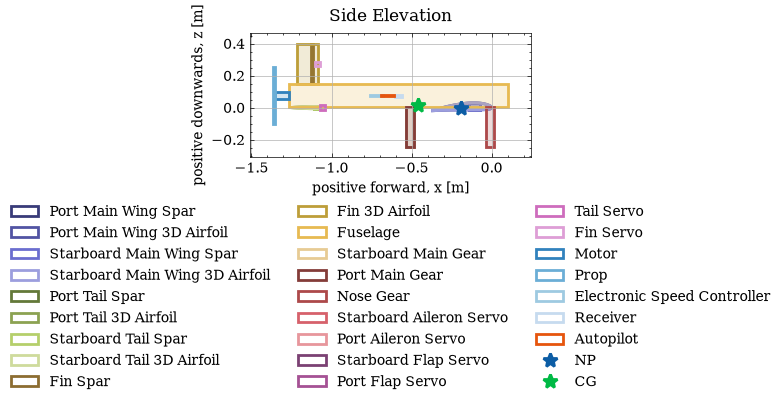

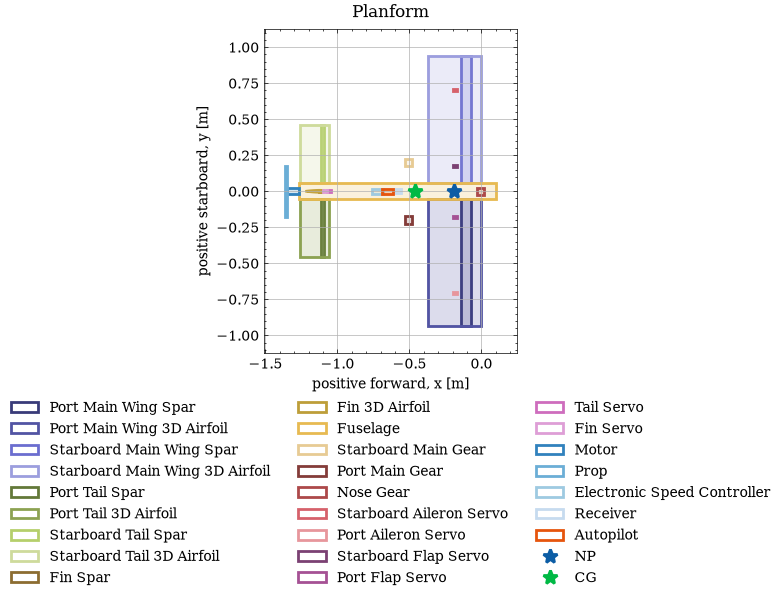

Aircraft.mass-breakdown
                                        Name  Mass [kg] Mass Factor  X Position [m]  Y Position [m]  Z Position [m]
                                    Aircraft      2.213         N/A          -0.459           0.000           0.014
                     Aircraft.Port Main Wing      0.401         N/A          -0.124          -0.496           0.001
                Aircraft.Port Main Wing.Spar      0.240       1.200          -0.108          -0.496           0.007
          Aircraft.Port Main Wing.3D Airfoil      0.161       1.200          -0.148          -0.496          -0.008
     Aircraft.Port Main Wing.3D Airfoil.Spar      0.240       1.200          -0.108          -0.496           0.007
                Aircraft.Starboard Main Wing      0.401         N/A          -0.124           0.496           0.001
           Aircraft.Starboard Main Wing.Spar      0.240       1.200          -0.108           0.496           0.007
     Aircraft.Starboard Main Wing.3D Airfoil    

<Table Aircraft.mass-breakdown>

In [17]:
gear = GearSizing(
    aircraft=aircraft,
    configuration="fwd tricycle",
    nose_weighting=10,
    main_weighting=90,
    gear=Gear(
        mass=Mass(100 / 1000),
        dx=50 / 1000,
        dy=50 / 1000,
        dz=250 / 1000,
        CD_0=0.001 # assumed
    ),
    main_position=-50 / 1000,
    lateral_position=200 / 1000
)

aircraft.add_gear(gear)

aircraft.plots.side_elevation(show=True, save=False)
aircraft.plots.planform(show=True, save=False, figsize=(6, 6))
aircraft.info.mass_breakdown(show=True, save=False)

### Payload Sizing

* Positioned automatically to meet static margin requirements

In [18]:
payload = PayloadSizing(
    payload=Payload(
        mass=Mass(2000 / 1000, override_mass_factor=1),
        fixed_center=Position(z=100 / 1000),
        dx=200 / 1000,
        dy=100 / 1000,
        dz=100 / 1000
    ),
    SM=0.15
)
aircraft.add_payload(payload)

[fin] iter: 0, fin arm error: 18.00mm
[fin] iter: 1, fin arm error: 0.16mm
[tail] iter: 0, tail arm error: 42.47mm
[tail] iter: 1, tail arm error: 7.15mm
[tail] iter: 2, tail arm error: 1.19mm
[tail] iter: 3, tail arm error: 0.20mm
[nose gear] iter: 0, nose gear position delta: 405.97mm
[nose gear] iter: 1, nose gear position delta: 11.78mm
[nose gear] iter: 2, nose gear position delta: 0.33mm
[main gear] iter: 0, main gear position delta: 116.34mm
[nose gear] iter: 0, nose gear position delta: 420.05mm
[nose gear] iter: 1, nose gear position delta: 0.06mm
[main gear] iter: 1, main gear position delta: 34.43mm
[nose gear] iter: 0, nose gear position delta: 420.22mm
[nose gear] iter: 1, nose gear position delta: 0.00mm
[main gear] iter: 2, main gear position delta: 2.01mm
[nose gear] iter: 0, nose gear position delta: 420.23mm
[nose gear] iter: 1, nose gear position delta: 0.00mm
[main gear] iter: 3, main gear position delta: 0.12mm
[payload] iter: 0, static margin error: 0.285
[fin] it

### Battery Sizing

[prop] iter: 0, battery mass error: 4588.48g
[prop] iter: 0, battery mass error: 0.00g
[fin] iter: 0, fin arm error: 0.23mm
[tail] iter: 0, tail arm error: 2.79mm
[tail] iter: 1, tail arm error: 0.45mm
[nose gear] iter: 0, nose gear position delta: 302.64mm
[nose gear] iter: 1, nose gear position delta: 0.31mm
[main gear] iter: 0, main gear position delta: 196.77mm
[nose gear] iter: 0, nose gear position delta: 302.27mm
[nose gear] iter: 1, nose gear position delta: 0.00mm
[main gear] iter: 1, main gear position delta: 0.91mm
[fin] iter: 0, fin arm error: 3.82mm
[fin] iter: 1, fin arm error: 0.03mm
[tail] iter: 0, tail arm error: 5.72mm
[tail] iter: 1, tail arm error: 0.92mm
[nose gear] iter: 0, nose gear position delta: 347.73mm
[nose gear] iter: 1, nose gear position delta: 1.18mm
[nose gear] iter: 2, nose gear position delta: 0.03mm
[main gear] iter: 0, main gear position delta: 154.51mm
[nose gear] iter: 0, nose gear position delta: 349.13mm
[nose gear] iter: 1, nose gear position 

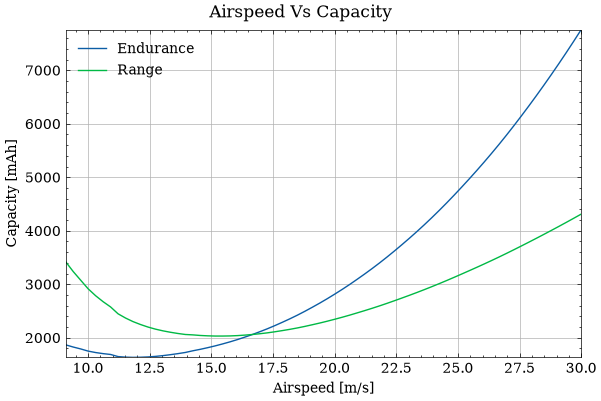

Aircraft.overview
                            Mass  4.605408
                          CL_max     1.641
                            CD_0     0.017
              Lift-to-Drag Ratio    13.467
            Stall Airspeed [m/s]     8.308
    Optimal Range Airspeed [m/s]    15.172
Optimal Endurance Airspeed [m/s]    11.528
                   Static Margin     0.150
Aircraft.mass-breakdown
                                        Name  Mass [kg] Mass Factor  X Position [m]  Y Position [m]  Z Position [m]
                                    Aircraft      4.605         N/A          -0.112           0.000           0.056
                     Aircraft.Port Main Wing      0.401         N/A          -0.124          -0.496           0.001
                Aircraft.Port Main Wing.Spar      0.240       1.200          -0.108          -0.496           0.007
          Aircraft.Port Main Wing.3D Airfoil      0.161       1.200          -0.148          -0.496          -0.008
     Aircraft.Port Main Wing.3D Ai

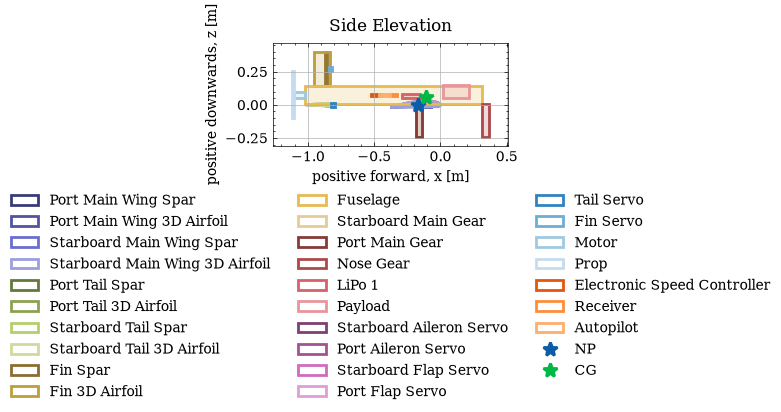

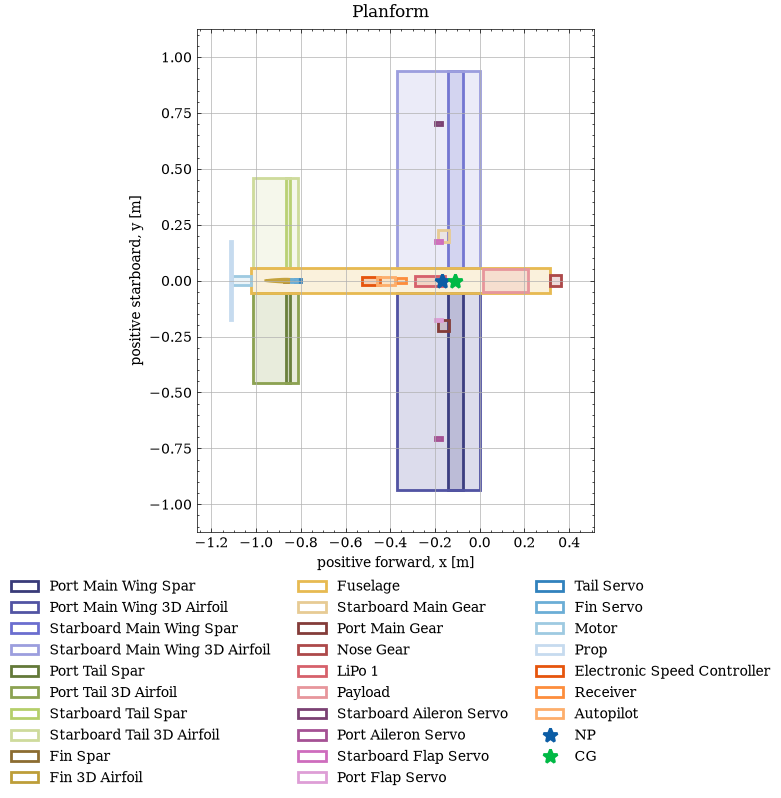

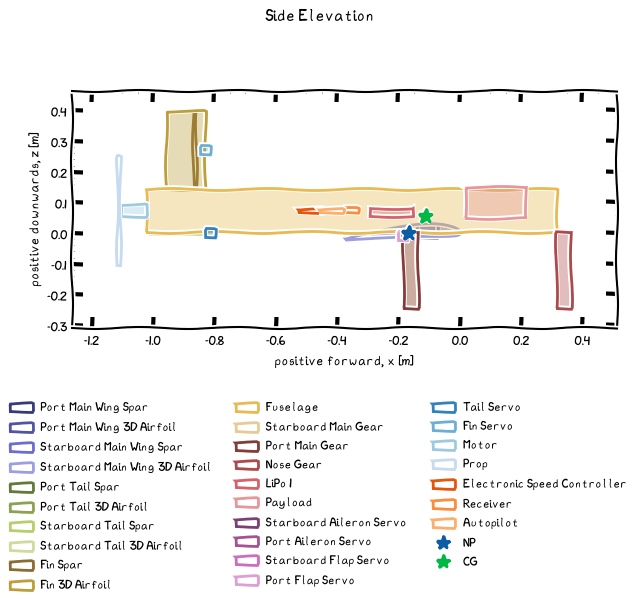

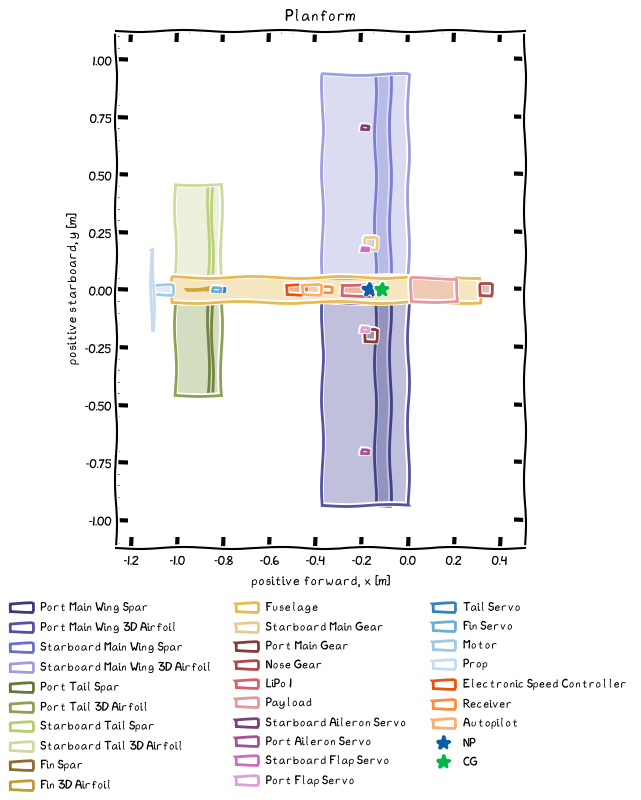

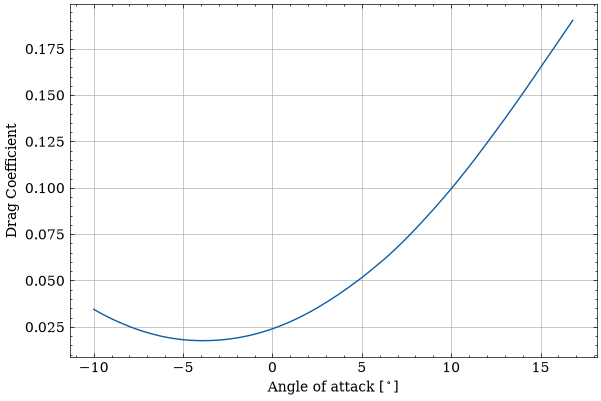

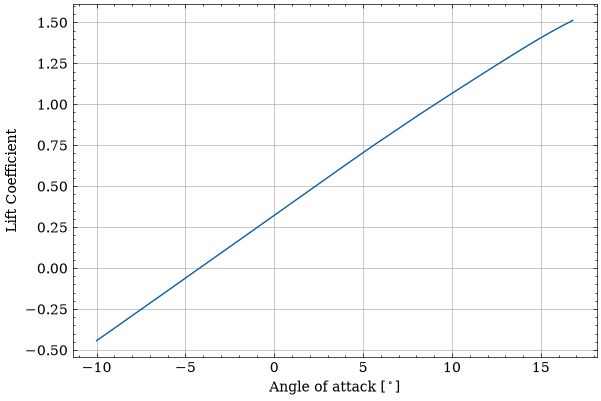

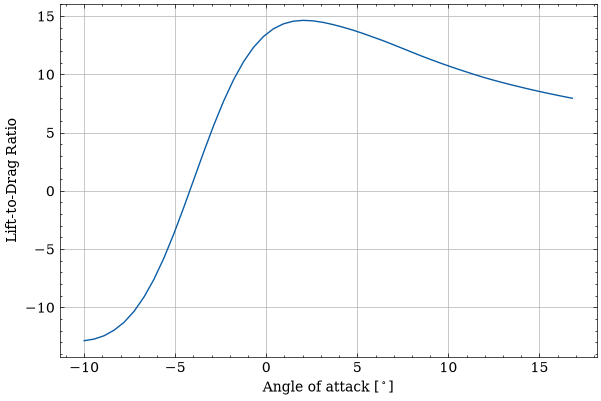

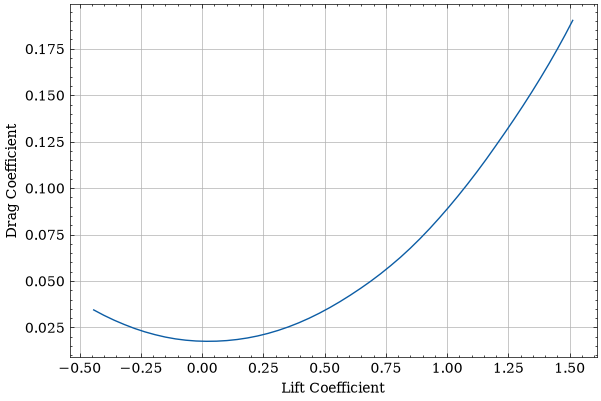

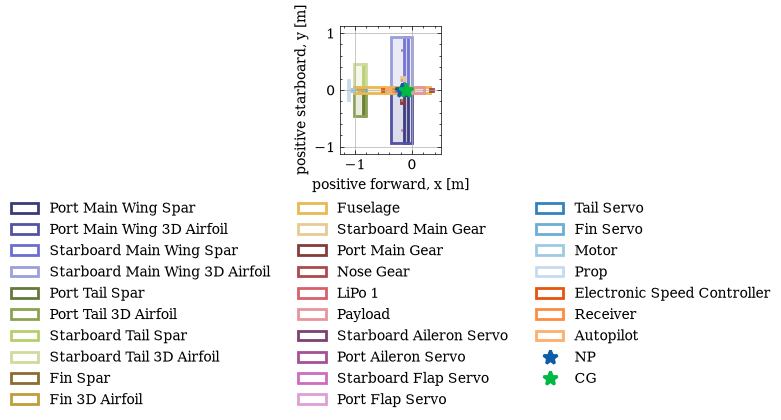

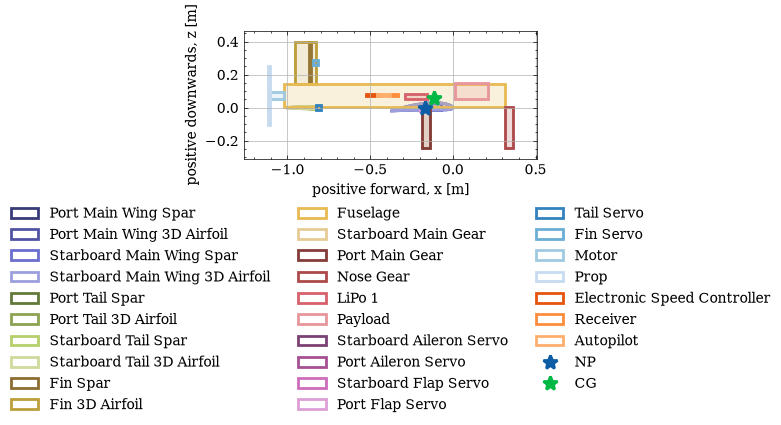

In [19]:
# Battery Sizing

# arbitrarily based on https://sussex-model-centre.co.uk/products/overlander-super-sport-3900mah-4s-14-8v-35c-lipo-battery
# ! actual battery needs to be determined
lipo = LiPo(
    component_name="LiPo",
    mass=Mass(368 / 1000, override_mass_factor=1.1),
    dynamic_center=lambda: Position(
        x=aircraft.np + aircraft.port_main_wing.airfoil3D.chordwise_position(payload.SM).x, z=137 / 2000
    ), # cg without calling cg
    dx=137 / 1000,
    dy=44 / 1000,
    dz=27 / 1000,
    n_cells=4,
    capacity=3900 / 1000,
)

ps = PropulsionSizing(
    aircraft=aircraft,
    lipo=lipo,
    airspeed=15,
    range=20000,
    endurance=20,
    speed_controller_efficiency=0.98,
    motor_efficiency=0.85,
    propulsive_efficiency=0.65
)
aircraft.add_lipos(ps)

aircraft.resize()

print(f"Aircraft angle of attack for level-steady flight: {ps.alpha_req:.2f} deg")
print(f"Fractional LiPo's required: {ps.factional_LiPos_req:.2f}")
print(f"LiPo's required {ps.LiPos_req}")

ps.plots.airspeed_vs_capacity(show=True, save=False)

aircraft.info.overview(show=True, save=False, transpose=True) # type: ignore
aircraft.info.mass_breakdown(show=True, save=False)
side_elevation_fig = aircraft.plots.side_elevation(show=True, save=False)
planform_fig = aircraft.plots.planform(show=True, save=False, figsize=(6, 8))
side_elevation_fig.show(xkcd=True, figsize=(6, 6))
planform_fig.show(xkcd=True, figsize=(6, 8))
aircraft.plots.all(show=True, save=False)

### Stability Analysis

- Elevator angle for trim

StabilityAnalysis(name='stability-analysis', V_bar_T=0.5, a=np.float64(4.255738118089302), a_1=np.float64(3.8948020864738826), a_2=np.float64(2.6242715752927652), a_3=0.0, Cm_0=-0.1031, CL_w=array([-0.5       , -0.45918367, -0.41836735, -0.37755102, -0.33673469,
       -0.29591837, -0.25510204, -0.21428571, -0.17346939, -0.13265306,
       -0.09183673, -0.05102041, -0.01020408,  0.03061224,  0.07142857,
        0.1122449 ,  0.15306122,  0.19387755,  0.23469388,  0.2755102 ,
        0.31632653,  0.35714286,  0.39795918,  0.43877551,  0.47959184,
        0.52040816,  0.56122449,  0.60204082,  0.64285714,  0.68367347,
        0.7244898 ,  0.76530612,  0.80612245,  0.84693878,  0.8877551 ,
        0.92857143,  0.96938776,  1.01020408,  1.05102041,  1.09183673,
        1.13265306,  1.17346939,  1.21428571,  1.25510204,  1.29591837,
        1.33673469,  1.37755102,  1.41836735,  1.45918367,  1.5       ]), h=np.float64(-0.3014300796951318), h_0=-0.24965738368864346, downwash_gradient=np.float

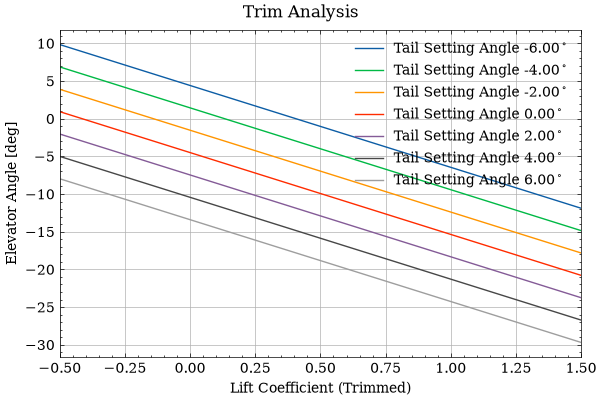

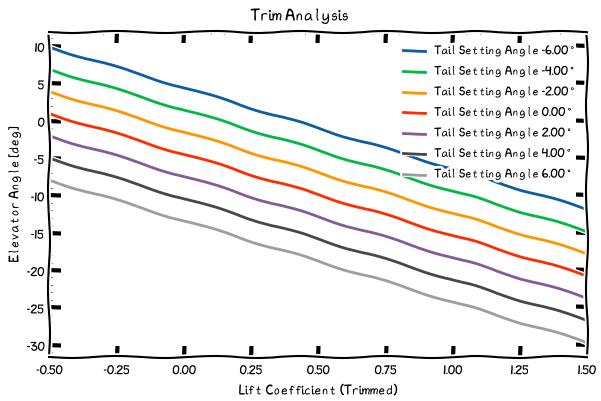

<Plots stability-analysis.trim-analysis>

In [20]:
main_wing = aircraft.port_main_wing
tail_wing = aircraft.port_tail_wing

chord = main_wing.airfoil3D.chord

import numpy as np

sa = StabilityAnalysis(
    V_bar_T=tail.volume_coefficient,
    a=main_wing.airfoil3D.solvers.finite_wing.a,
    a_1=tail_wing.airfoil3D.solvers.finite_wing.a,
    elevator_chord_fraction=0.3,
    Cm_0=main_wing.airfoil3D.solvers.finite_wing.CM(main_wing.airfoil3D.airfoil2d.alpha_L0),
    CL_w=np.linspace(-0.5, 1.5, 50),
    h=aircraft.cg / chord,
    h_0=main_wing.airfoil3D.aerodynamic_center.x / chord,
    downwash_gradient=main_wing.downwash_gradient,
    eta_T_deg=np.linspace(-6, 6, 7),
)

print(sa)

sa.plots.trim_analysis(show=True, save=False)
sa.plots.trim_analysis(show=True, save=False, xkcd=True)